# 06 · Selección final, evaluación e interpretación

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `rectangular-masked-v3-2026-11-22`.

El criterio se congela antes de reevaluar test. El test de 237 imágenes ya se examinó en v2; esta reevaluación es descriptiva y no una nueva confirmación independiente.

Este cuaderno contiene el código ejecutable de la etapa, dividido en celdas con explicación. Ejecutar de arriba hacia abajo. Los notebooks se recorren del 01 al 06; los ajustes y las curvas pueden tardar varios minutos.

## 1. Librerías y ubicación del proyecto

Se cargan las bibliotecas utilizadas y se localiza la carpeta raíz. La misma celda funciona al abrir el notebook desde la raíz o desde `notebooks`. No entrena ningún modelo.

In [1]:
from pathlib import Path
import sys, json, hashlib, shutil, time, warnings, copy
import numpy as np
import pandas as pd
import cv2
import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/workflow.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    cohen_kappa_score,
)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.base import clone
from xgboost import XGBClassifier
from src.features import FEATURE_COUNT, PREPROCESSING_SPEC
from src.models import SVDSubspaceClassifier


## 2. Configuración y carpetas de salida

Se fija la semilla, el orden de las cinco etiquetas y las rutas de matrices, informes y modelos. Crear estas carpetas no modifica las radiografías originales.

In [2]:
DATA = ROOT / "data/processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
MODELS = ROOT / "models"
LABELS = ["Normal", "Dudosa", "Leve", "Moderada", "Severa"]
SEED = 42
PROTOCOL = "rectangular-masked-v3-2026-11-22"
for folder in [DATA, REPORTS, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Proyecto:", ROOT)
print("Protocolo:", PROTOCOL)


Proyecto: <proyecto-rodilla>
Protocolo: rectangular-masked-v3-2026-11-22


## 3. Guardar resultados y mostrar las figuras

La primera función exporta JSON evitando NaN/Infinity. La segunda guarda cada gráfico y lo muestra dentro del notebook, para que el documento conserve código y salida al verse en GitHub.

In [3]:
def save_json(path, value):
    def finite(item):
        if isinstance(item, dict):
            return {k: finite(v) for k, v in item.items()}
        if isinstance(item, (list, tuple)):
            return [finite(v) for v in item]
        if isinstance(item, np.generic):
            item = item.item()
        if isinstance(item, float) and not np.isfinite(item):
            return None
        return item

    Path(path).write_text(
        json.dumps(
            finite(value), ensure_ascii=False, indent=2, allow_nan=False, default=str
        ),
        encoding="utf-8",
    )


def figure(name):
    path = FIGURES / name
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(path)))


## 4. Lectura de matrices y función de métricas

Se comprueba la versión y se definen las mismas métricas utilizadas en los candidatos. El formato tabular tiene 288 entradas y el de píxeles, 2.304.

In [4]:
def arrays():
    payload = np.load(DATA / "features_arrays.npz")
    if "protocol" not in payload or str(payload["protocol"]) != PROTOCOL:
        raise ValueError(
            "Matrices de otra versión; ejecutar antes el preprocesamiento."
        )
    return payload


def score(y, pred):
    return {
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 4),
        "Balanced Acc (%)": round(balanced_accuracy_score(y, pred) * 100, 4),
        "F1 Macro": round(f1_score(y, pred, average="macro", zero_division=0), 6),
        "F1 Weighted": round(f1_score(y, pred, average="weighted", zero_division=0), 6),
        "Precision Macro": round(
            precision_score(y, pred, average="macro", zero_division=0), 6
        ),
        "Recall Macro": round(
            recall_score(y, pred, average="macro", zero_division=0), 6
        ),
    }


## 5. Reunir los 33 candidatos de validación

Se leen las puntuaciones de los tres notebooks anteriores y sus modelos ajustados. El orden se define por F1 macro de validación, no por test.

In [5]:
a = arrays()

rows = []

models = {}

for file in ["baseline_validation", "advanced_validation", "feature_validation"]:
    rows += json.loads((REPORTS / (file + ".json")).read_text(encoding="utf-8"))
    models.update(joblib.load(MODELS / (file + "_candidates.joblib")))

validation = pd.DataFrame(rows).sort_values("F1 Macro", ascending=False, kind="stable")

validation.to_csv(REPORTS / "validation_comparison.csv", index=False)

display(validation[["Modelo", "family", "F1 Macro"]])


,Modelo,family,F1 Macro
6,SVM RBF C=1,SVM,0.629974
21,SVM ANOVA80 C=50,SVM,0.625267
22,SVM PCA64 C=10,SVM,0.618292
7,XGBoost 200 rondas,XGBoost,0.617142
8,XGBoost 300 rondas,XGBoost,0.616885
9,SVM RBF C=50,SVM,0.613015
23,SVM PCA32 C=10,SVM,0.611749
10,SVM RBF C=10,SVM,0.611277
24,SVM ANOVA160 C=10,SVM,0.603059
25,SVM PCA128 C=10,SVM,0.600281


## 6. Congelar la decisión elegida

Se elige la mejor fila global y la mejor por familia, y se guarda la decisión antes de calcular nuevas predicciones de test. Se declara expresamente que el test ya se había examinado en v2.

In [6]:
winner = validation.iloc[0]

chosen = winner.Modelo

save_json(
    REPORTS / "selection_decision.json",
    dict(
        protocol=PROTOCOL,
        selected_model=chosen,
        selection_metric="F1 macro validation",
        validation_f1=float(winner["F1 Macro"]),
        test_used_for_selection=False,
        test_previously_evaluated=True,
        evaluation_note="Reevaluación descriptiva del mismo test tras cambiar preprocesamiento; no es un nuevo test independiente.",
    ),
)

family_winners = validation.drop_duplicates("family")

print("Elegido por validación:", chosen)


Elegido por validación: SVM RBF C=1


## 7. Reentrenar con train más validación y predecir test

Se clona cada ganador de familia, se reajusta con 1.339 imágenes y se evalúa en las 237 de test. El escalador/selector se reajusta con train+validación y no con test.

In [7]:
test_rows = []

predictions = {}

final_models = {}

for row in family_winners.itertuples():
    model = clone(models[row.Modelo])
    kind = row.input_kind
    X = np.vstack([a[f"X_train_{kind}"], a[f"X_val_{kind}"]])
    y = np.r_[a["y_train"], a["y_val"]]
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=FutureWarning)
        model.fit(X, y)
    pred = model.predict(a[f"X_test_{kind}"])
    prob = model.predict_proba(a[f"X_test_{kind}"])
    entry = dict(
        Modelo=row.Modelo,
        family=row.family,
        validation_f1=(
            float(getattr(row, "_3", 0))
            if False
            else float(validation[validation.Modelo == row.Modelo]["F1 Macro"].iloc[0])
        ),
        **score(a["y_test"], pred),
    )
    test_rows.append(entry)
    predictions[row.Modelo] = (pred, prob)
    final_models[row.Modelo] = model
    print("TEST", row.Modelo, entry["F1 Macro"], flush=True)


TEST SVM RBF C=1 0.715544
TEST XGBoost 200 rondas 0.70849
TEST Random Forest n=300 hoja=2 0.662749
TEST Logística C=0.01 0.67222
TEST SVD k=10 0.535781
TEST Dummy mayoritaria 0.094194


## 8. Serializar el pipeline final y su configuración

Se guarda el ganador elegido por validación, junto con configuración del extractor y parámetros. El objeto incluye las transformaciones aprendidas; la API comparte el extractor de imágenes.

In [8]:
table = pd.DataFrame(test_rows).sort_values("F1 Macro", ascending=False)

final = final_models[chosen]

joblib.dump(final, MODELS / "best_model.joblib")

selected_features = a["feature_names"].tolist()

if isinstance(final, Pipeline) and "select" in final.named_steps:
    selected_features = np.array(selected_features)[
        final.named_steps["select"].get_support()
    ].tolist()

hyper = dict(
    protocol=PROTOCOL,
    name=chosen,
    input_features=FEATURE_COUNT,
    input_kind=winner.input_kind,
    preprocessing=PREPROCESSING_SPEC,
    selected_features=selected_features,
    output_features=(
        int(final.named_steps["pca"].n_components_)
        if isinstance(final, Pipeline) and "pca" in final.named_steps
        else len(selected_features)
    ),
    parameters={
        k: v
        for k, v in final.get_params().items()
        if isinstance(v, (str, int, float, bool, type(None)))
    },
    selection="F1 macro en validación fija; test no usado para elegir",
)

save_json(MODELS / "hyperparameters.json", hyper)


## 9. Métricas globales, por clase y trazabilidad

Se calculan tablas, matriz absoluta, kappa cuadrático y predicciones por imagen. Ordenar la tabla por test es descriptivo: no redefine el modelo seleccionado.

In [9]:
final_row = next((x for x in test_rows if x["Modelo"] == chosen))

final_pred, final_prob = predictions[chosen]

report = classification_report(
    a["y_test"],
    final_pred,
    labels=range(5),
    target_names=LABELS,
    output_dict=True,
    zero_division=0,
)

table.to_csv(REPORTS / "comparacion_modelos.csv", index=False)

metrics = dict(
    project="Clasificación de artrosis de rodilla · ML1 FIUNA",
    protocol=PROTOCOL,
    selected_model=chosen,
    best_model=chosen,
    best_model_f1_macro=final_row["F1 Macro"],
    selection_rule="Mayor F1 macro en validación; selección congelada antes del test",
    comparison_table=test_rows,
    final_test=final_row,
    classification_report=report,
    confusion_matrix=confusion_matrix(a["y_test"], final_pred).tolist(),
    quadratic_kappa=float(
        cohen_kappa_score(a["y_test"], final_pred, weights="quadratic")
    ),
    test_size=len(a["y_test"]),
    best_observed_test_model=str(table.iloc[0].Modelo),
    feature_count=hyper["output_features"],
    input_features=FEATURE_COUNT,
    test_previously_evaluated=True,
    evaluation_note="Mismo test ya evaluado en v2; resultado descriptivo, sin confirmación independiente.",
    preprocessing=PREPROCESSING_SPEC,
    audit=json.loads((REPORTS / "data_quality_audit.json").read_text(encoding="utf-8")),
)

save_json(REPORTS / "modelos_avanzados_metrics.json", metrics)

save_json(
    REPORTS / "per_sample_predictions.json",
    [
        dict(
            index=int(i), actual=int(y), predicted=int(p), probabilities=probs.tolist()
        )
        for i, (y, p, probs) in enumerate(zip(a["y_test"], final_pred, final_prob))
    ],
)

display(table)
display(pd.DataFrame(report).T)


,Modelo,family,validation_f1,Accuracy (%),Balanced Acc (%),F1 Macro,F1 Weighted,Precision Macro,Recall Macro
0,SVM RBF C=1,SVM,0.629974,71.3080,72.0899,0.715544,0.713221,0.711015,0.720899
1,XGBoost 200 rondas,XGBoost,0.617142,72.5738,70.3744,0.708490,0.719057,0.727891,0.703744
3,Logística C=0.01,Logística,0.550010,66.6667,69.2129,0.672220,0.664045,0.661014,0.692129
2,Random Forest n=300 hoja=2,Random Forest,0.572851,67.5105,66.8054,0.662749,0.664873,0.678306,0.668054
4,SVD k=10,SVD,0.462945,56.1181,53.8106,0.535781,0.560957,0.533819,0.538106
5,Dummy mayoritaria,Dummy,0.092508,30.8017,20.0000,0.094194,0.145066,0.061603,0.200000


,precision,recall,f1-score,support
Normal,0.764706,0.712329,0.737589,73.00000
Dudosa,0.676056,0.685714,0.680851,70.00000
Leve,0.647059,0.666667,0.656716,33.00000
Moderada,0.709677,0.733333,0.721311,30.00000
Severa,0.757576,0.806452,0.781250,31.00000
accuracy,0.713080,0.713080,0.713080,0.71308
macro avg,0.711015,0.720899,0.715544,237.00000
weighted avg,0.714243,0.713080,0.713221,237.00000


## 10. Comparación de F1 de test

Se compara la configuración elegida de cada familia. La selección se mantiene por validación aunque otra familia tenga mayor accuracy de test.

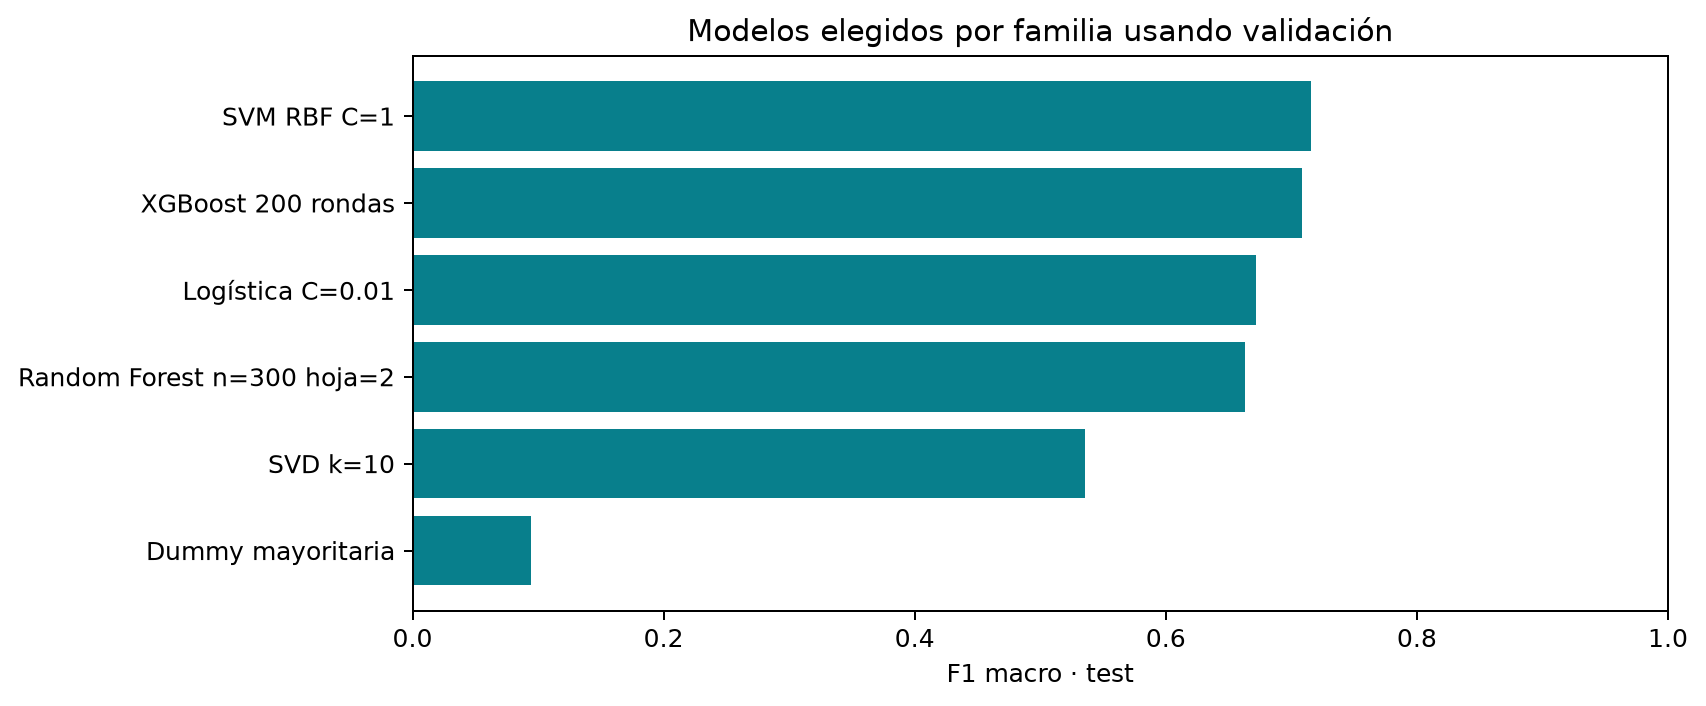

In [10]:
plt.figure(figsize=(9, 4))

plt.barh(table.Modelo[::-1], table["F1 Macro"][::-1], color="#087f8c")

plt.xlim(0, 1)

plt.xlabel("F1 macro · test")

plt.title("Modelos elegidos por familia usando validación")

figure("comparacion_modelos.png")


## 11. Matrices de confusión de todas las familias

Las filas representan clases reales y las columnas, predichas. Los conteos muestran el número de errores en cada grado.

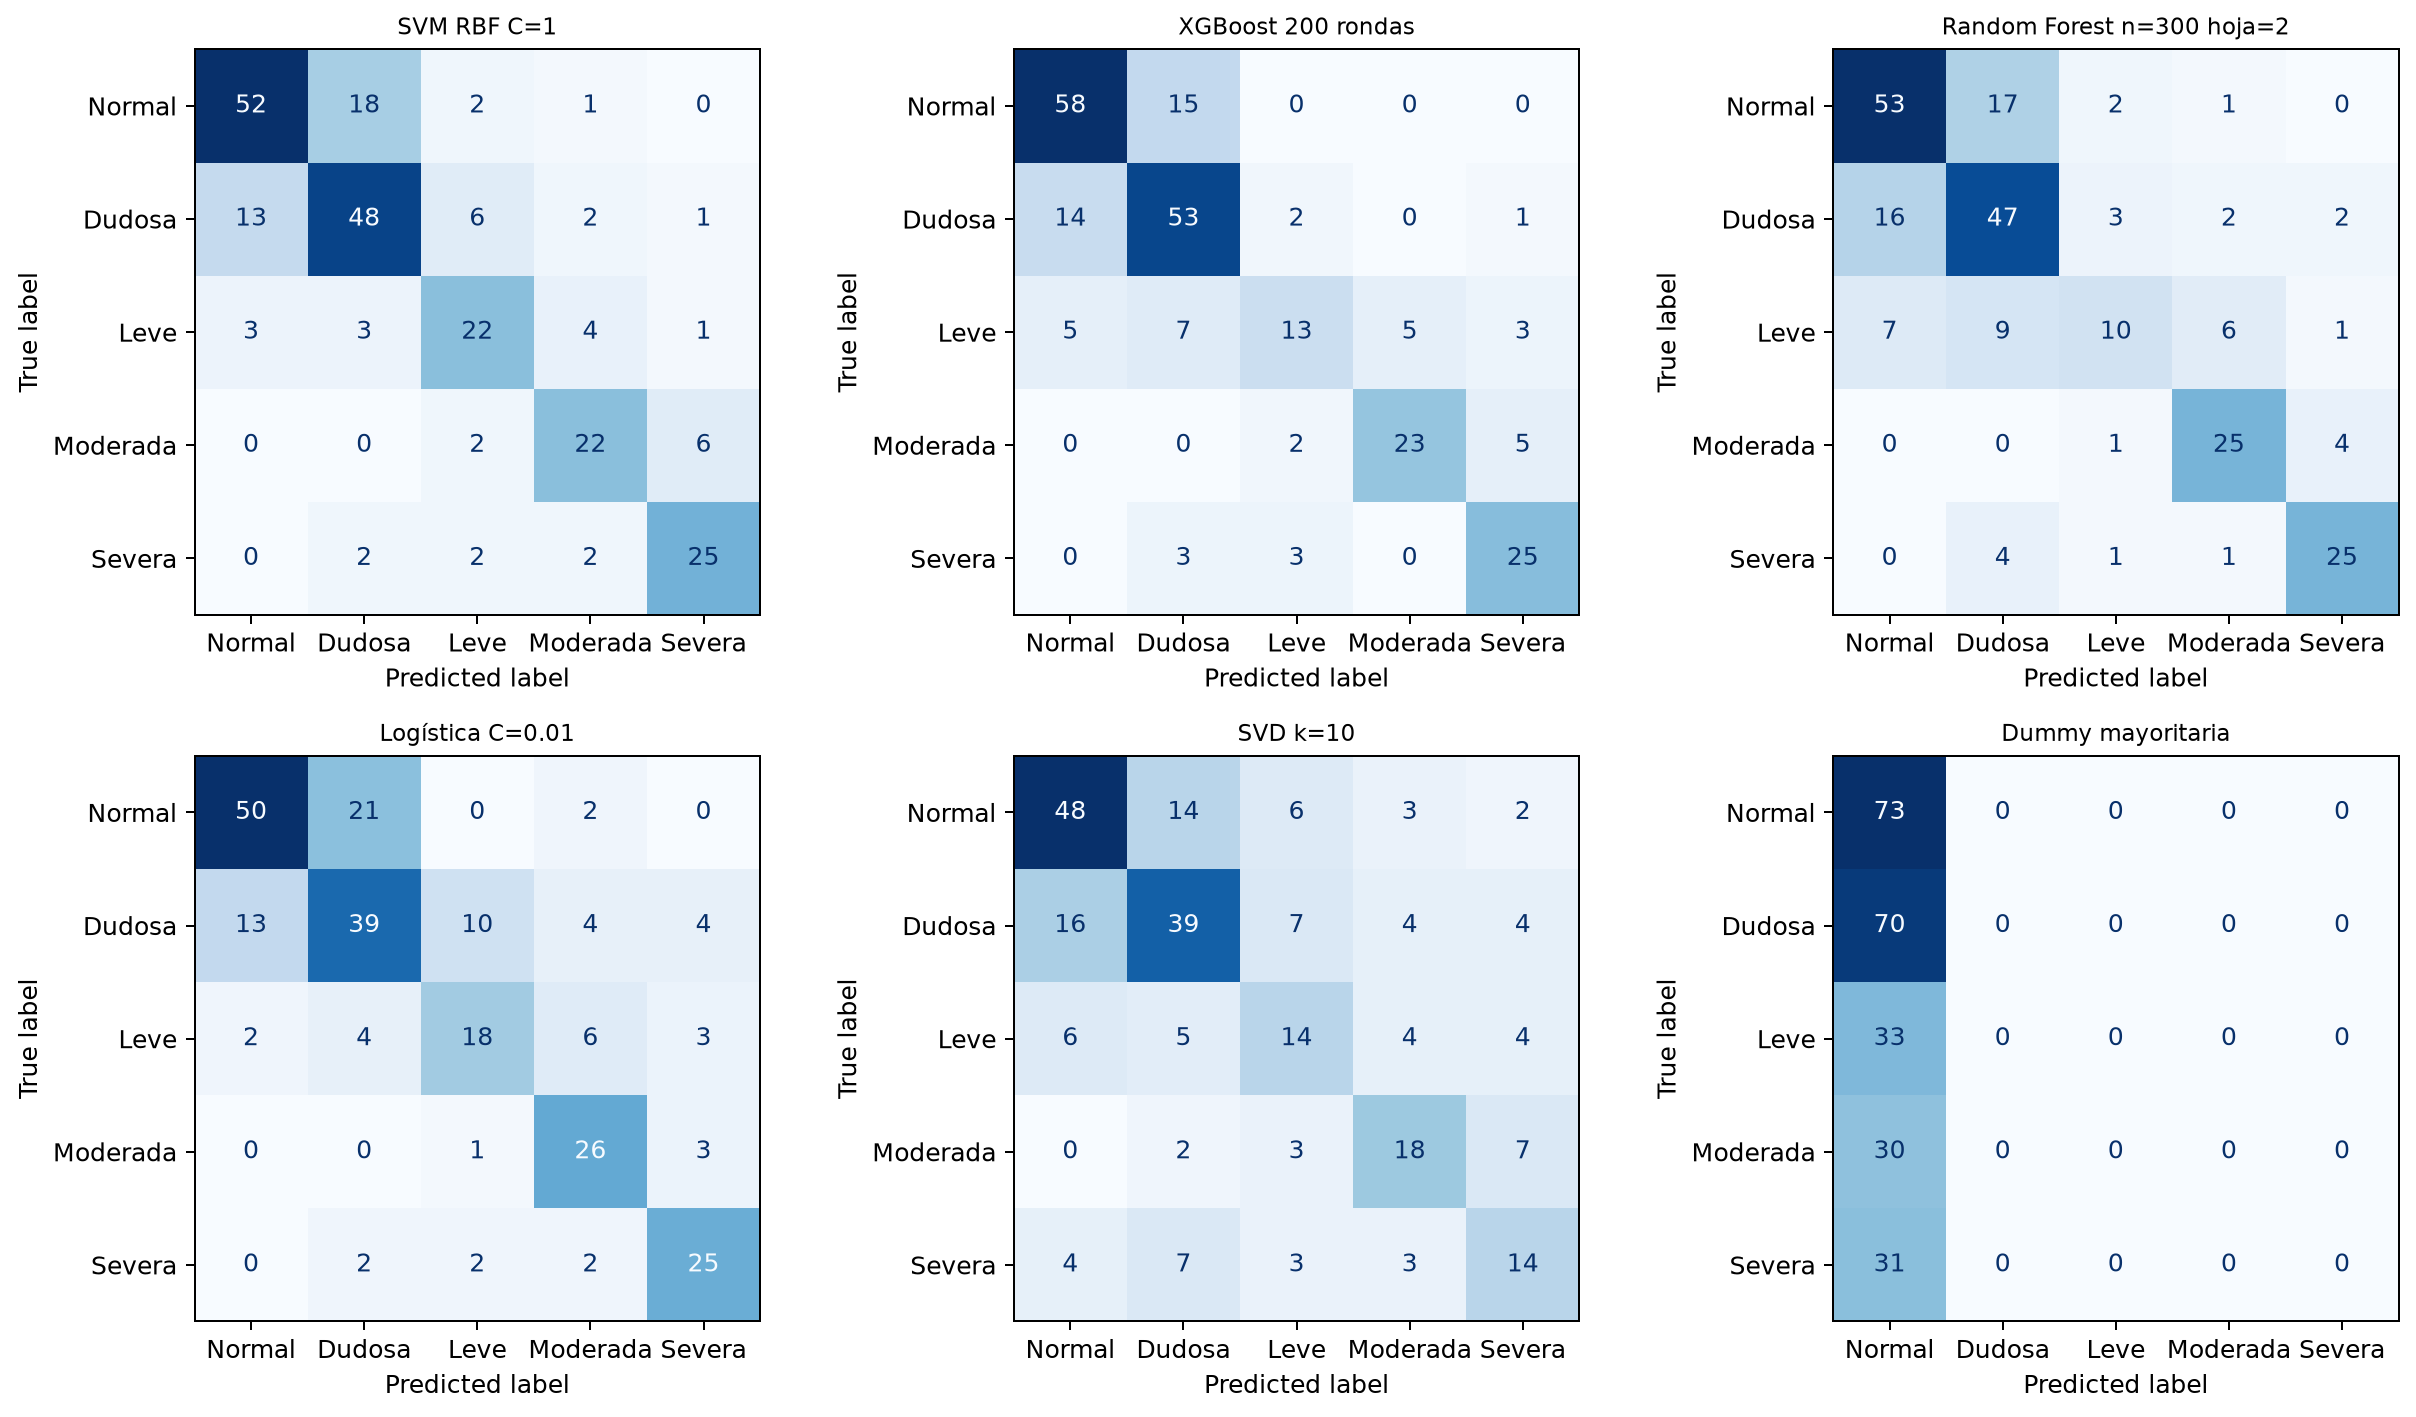

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (name, (pred, _)) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        a["y_test"], pred, display_labels=LABELS, cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name, fontsize=9)

for ax in list(axes.flat)[len(predictions) :]:
    ax.axis("off")

plt.tight_layout()

figure("modelos_avanzados_confusion_matrices.png")


## 12. Matriz normalizada del modelo final

Normalizar por fila permite comparar recall entre clases pese al desbalance. La diagonal es la fracción recuperada de cada clase real.

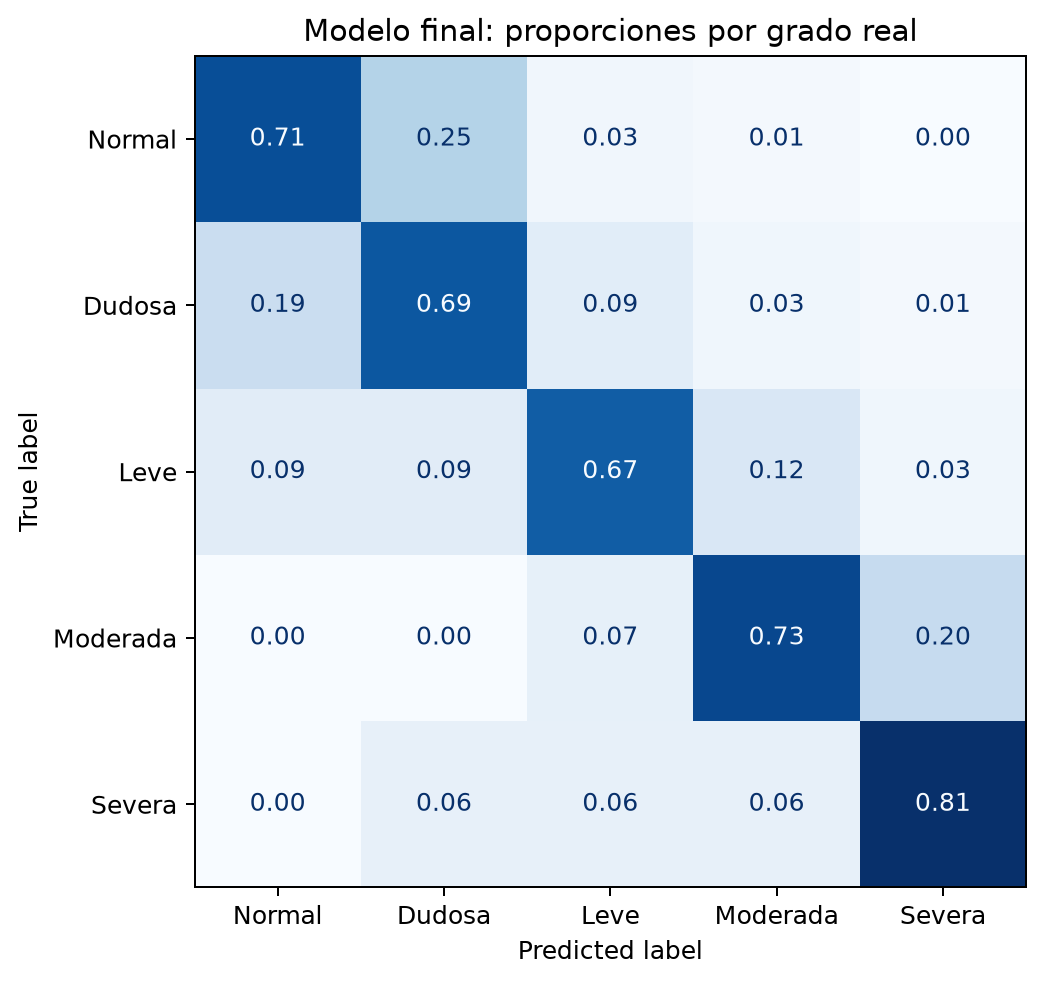

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    a["y_test"],
    final_pred,
    display_labels=LABELS,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax,
    colorbar=False,
)

ax.set_title("Modelo final: proporciones por grado real")

figure("final_confusion_normalizada.png")


## 13. Curvas ROC One-vs-Rest

Se binariza cada grado frente al resto y se recorren umbrales de sus puntuaciones. AUC no sustituye F1 multiclase ni demuestra calibración clínica.

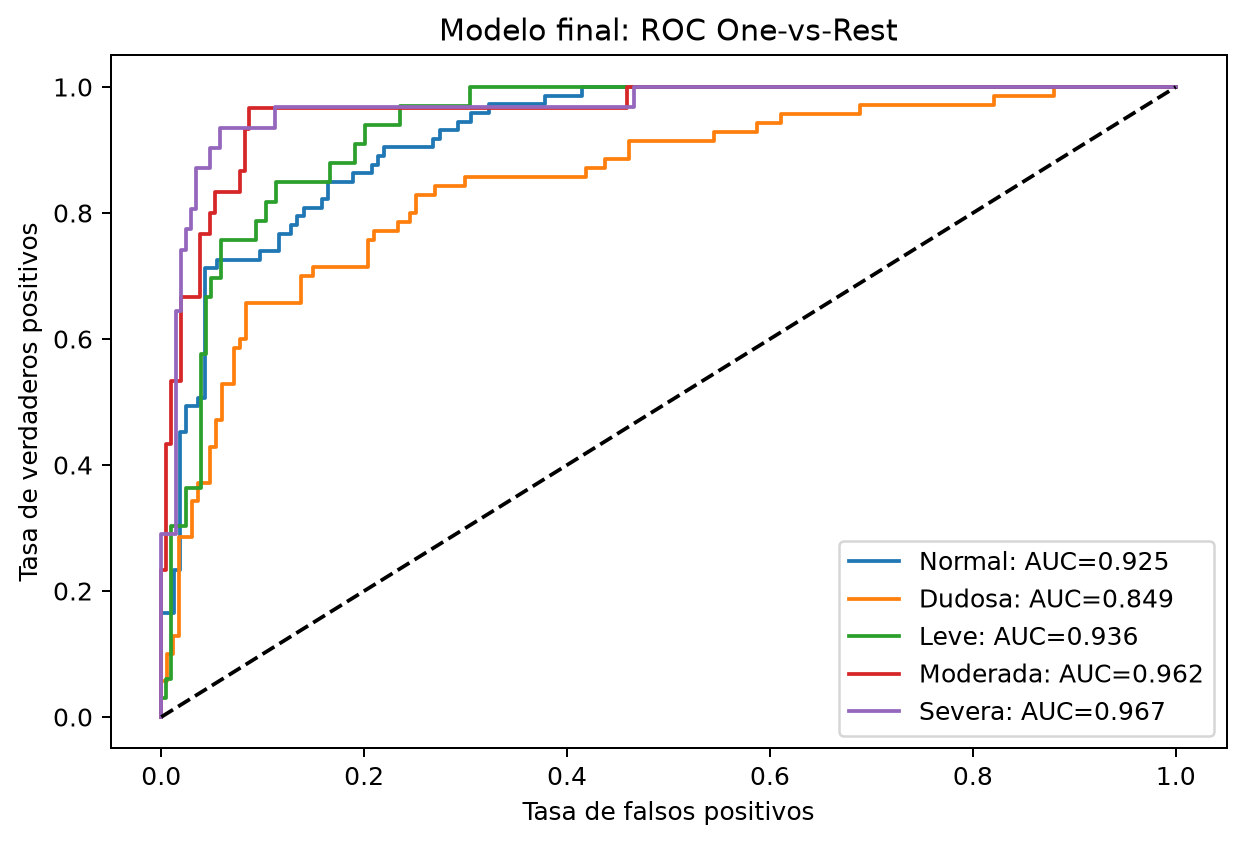

In [13]:
binary = label_binarize(a["y_test"], classes=range(5))

plt.figure(figsize=(8, 5))

for i, label in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(binary[:, i], final_prob[:, i])
    plt.plot(fpr, tpr, label=f"{label}: AUC={auc(fpr, tpr):.3f}")

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("Tasa de falsos positivos")

plt.ylabel("Tasa de verdaderos positivos")

plt.title("Modelo final: ROC One-vs-Rest")

plt.legend()

figure("modelos_avanzados_roc_curves.png")


## 14. Importancia del XGBoost comparado

La figura corresponde al árbol evaluado y no es una explicación causal del SVM final. Si el árbol utiliza ANOVA, se conserva la correspondencia con sus variables seleccionadas.

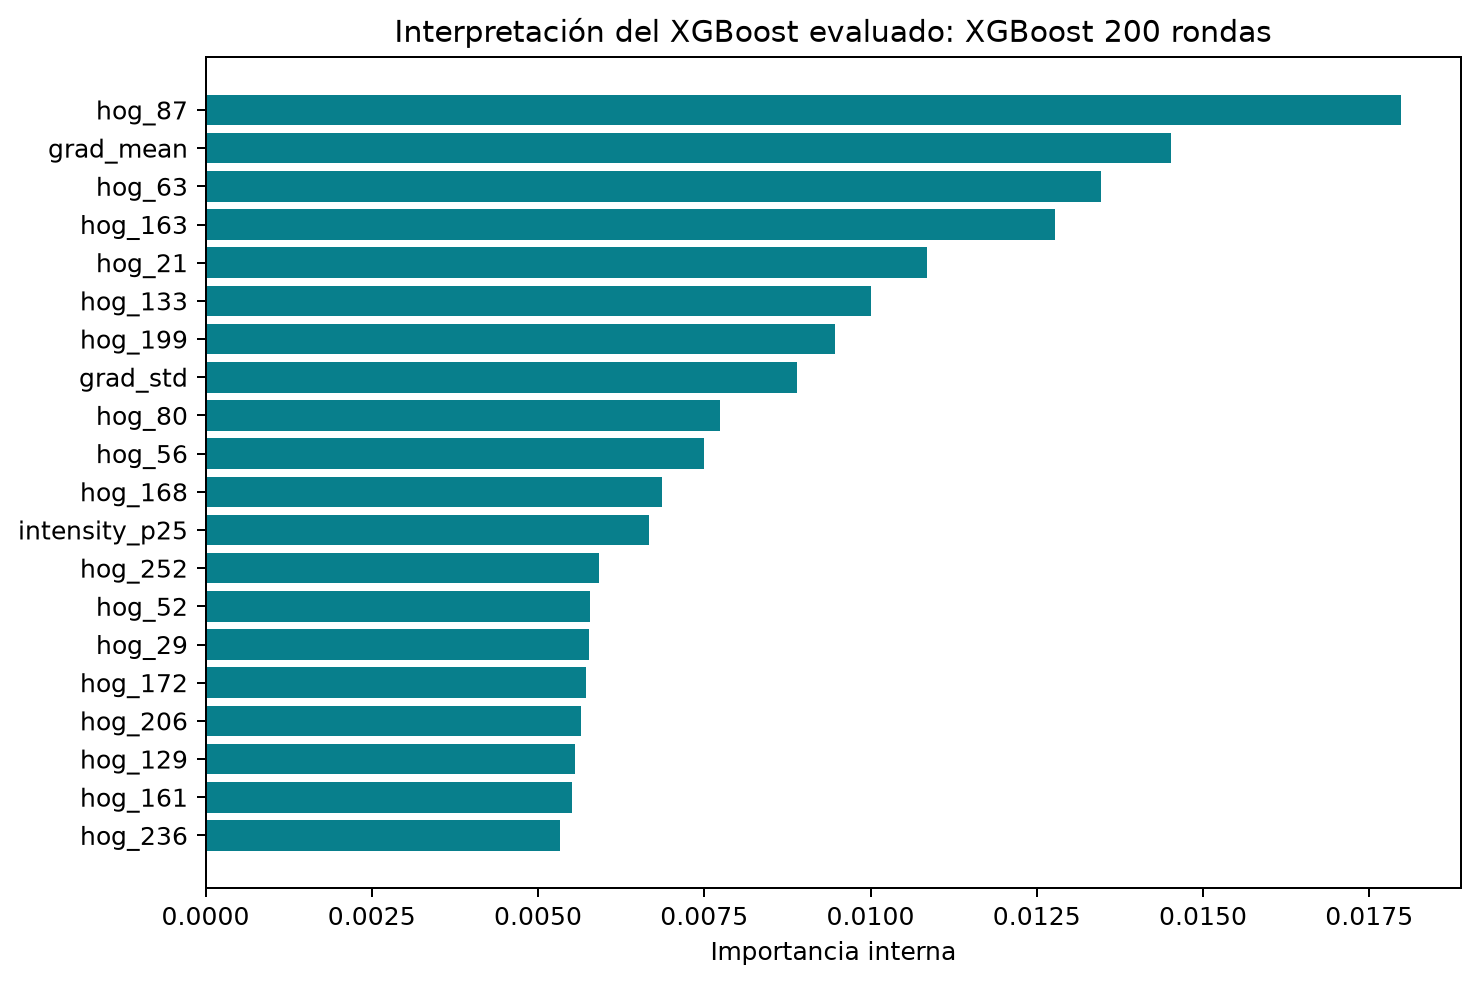

In [14]:
xgb_name = family_winners[family_winners.family == "XGBoost"].iloc[0].Modelo

tree = final_models[xgb_name]

names = a["feature_names"]

if isinstance(tree, Pipeline):
    if "select" in tree.named_steps:
        names = names[tree.named_steps["select"].get_support()]
    tree = tree.named_steps["clf"]

importance = tree.feature_importances_

order = np.argsort(importance)[-20:]

plt.figure(figsize=(9, 6))

plt.barh(np.array(names)[order], importance[order], color="#087f8c")

plt.xlabel("Importancia interna")

plt.title(f"Interpretación del XGBoost evaluado: {xgb_name}")

figure("modelos_avanzados_feature_importance.png")


## 15. Selección ANOVA y PCA: resultados de validación

Estas figuras vuelven a mostrar la comparación de representación usando exclusivamente validación; no se elige la dimensión a partir del resultado de test.

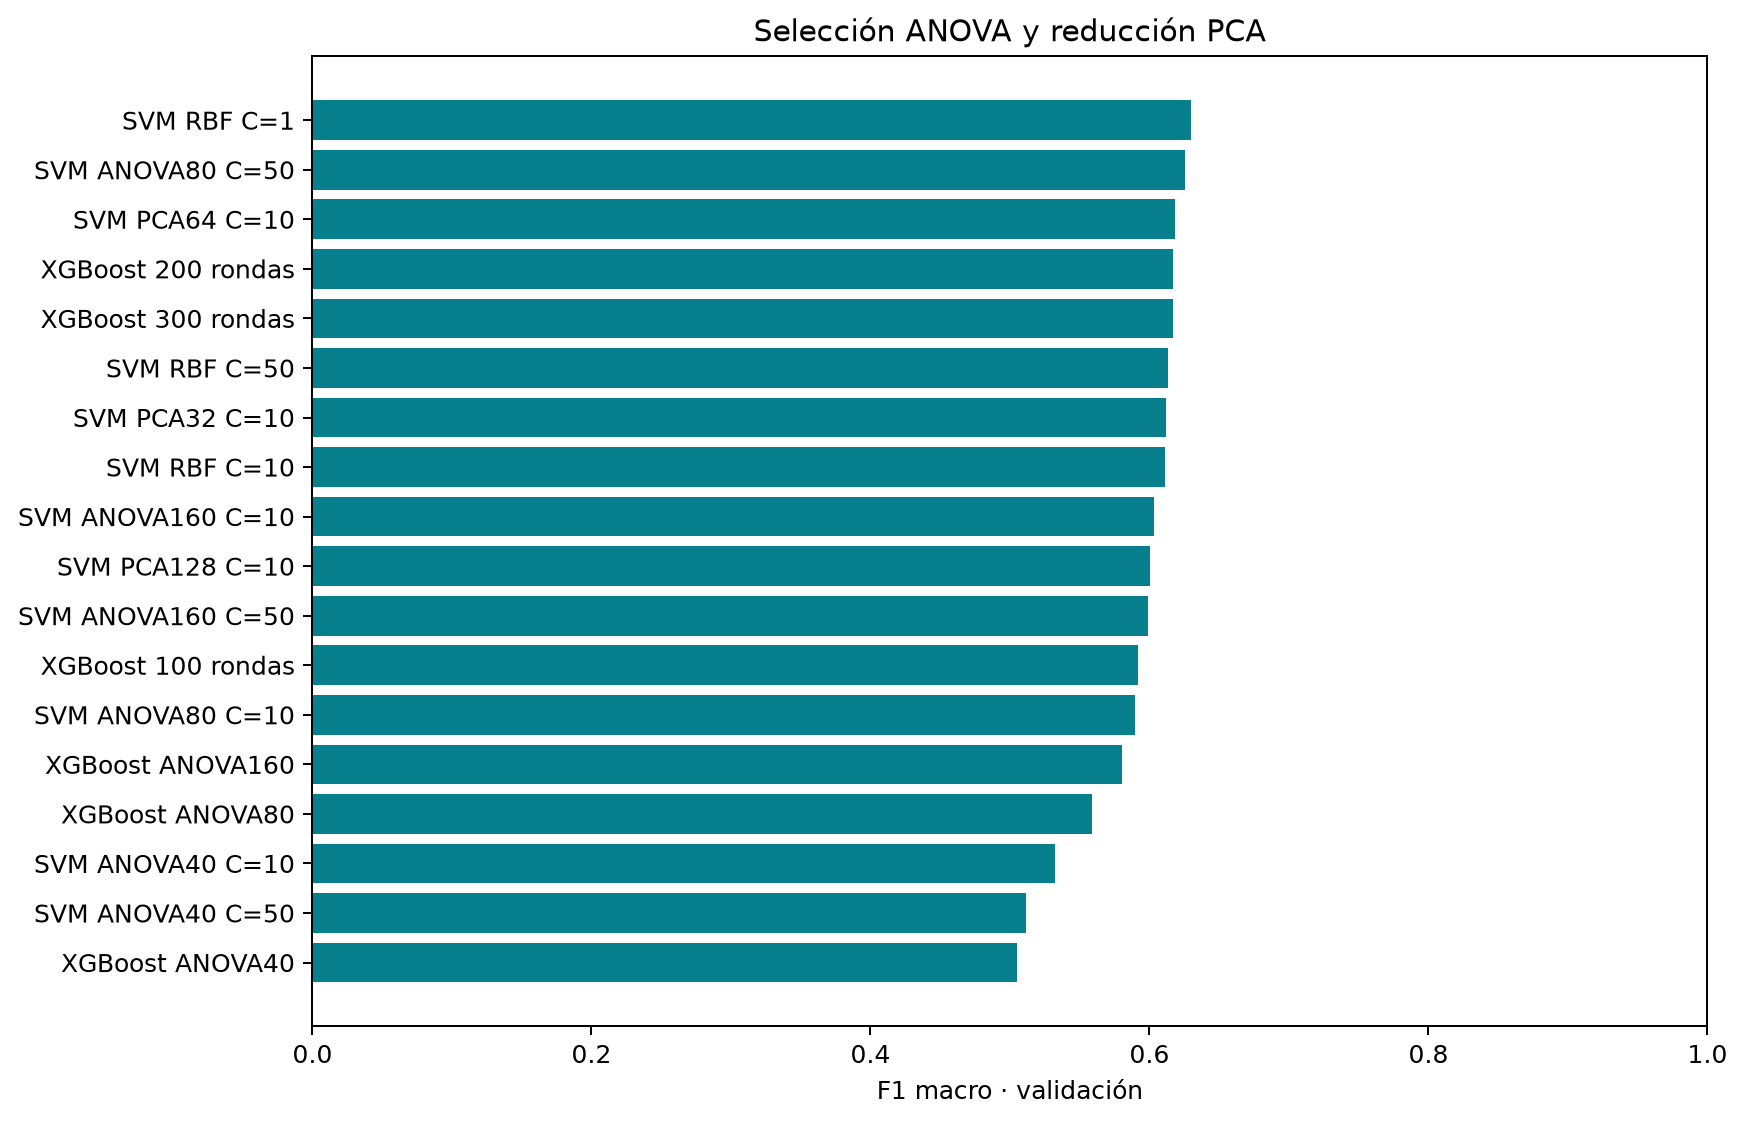

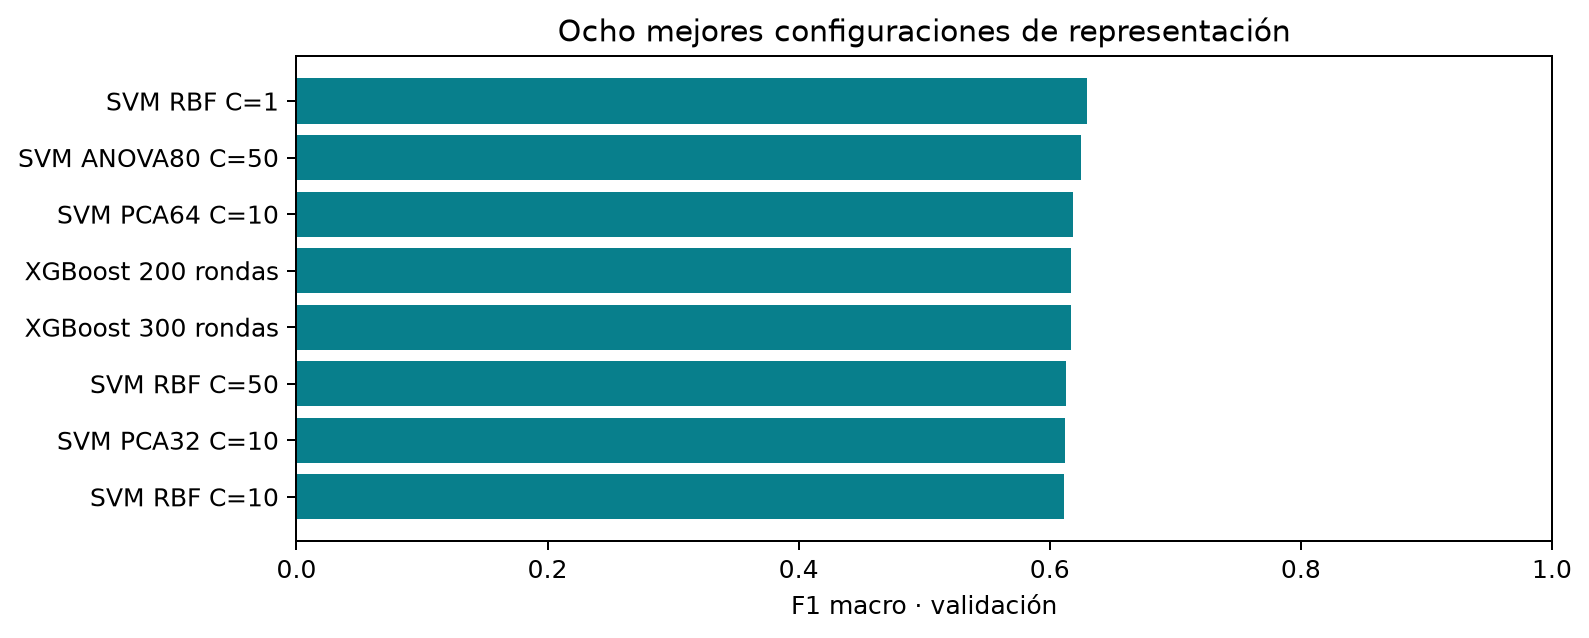

In [15]:
feat = validation[validation.family.isin(["SVM", "XGBoost"])]

plt.figure(figsize=(10, 7))

plt.barh(feat.Modelo[::-1], feat["F1 Macro"][::-1], color="#087f8c")

plt.xlabel("F1 macro · validación")

plt.xlim(0, 1)

plt.title("Selección ANOVA y reducción PCA")

figure("feature_engineering_validation.png")

top = feat.head(8)

plt.figure(figsize=(9, 3.5))

plt.barh(top.Modelo[::-1], top["F1 Macro"][::-1], color="#087f8c")

plt.xlim(0, 1)

plt.xlabel("F1 macro · validación")

plt.title("Ocho mejores configuraciones de representación")

figure("feature_engineering_summary.png")


## 16. Curvas de aprendizaje: código completo

Se usa StratifiedKFold de tres folds dentro de train, cuatro tamaños y clonación del Pipeline en cada ajuste. Es una celda costosa porque vuelve a entrenar varias veces. La banda es desviación entre folds, no un intervalo de confianza de generalización.

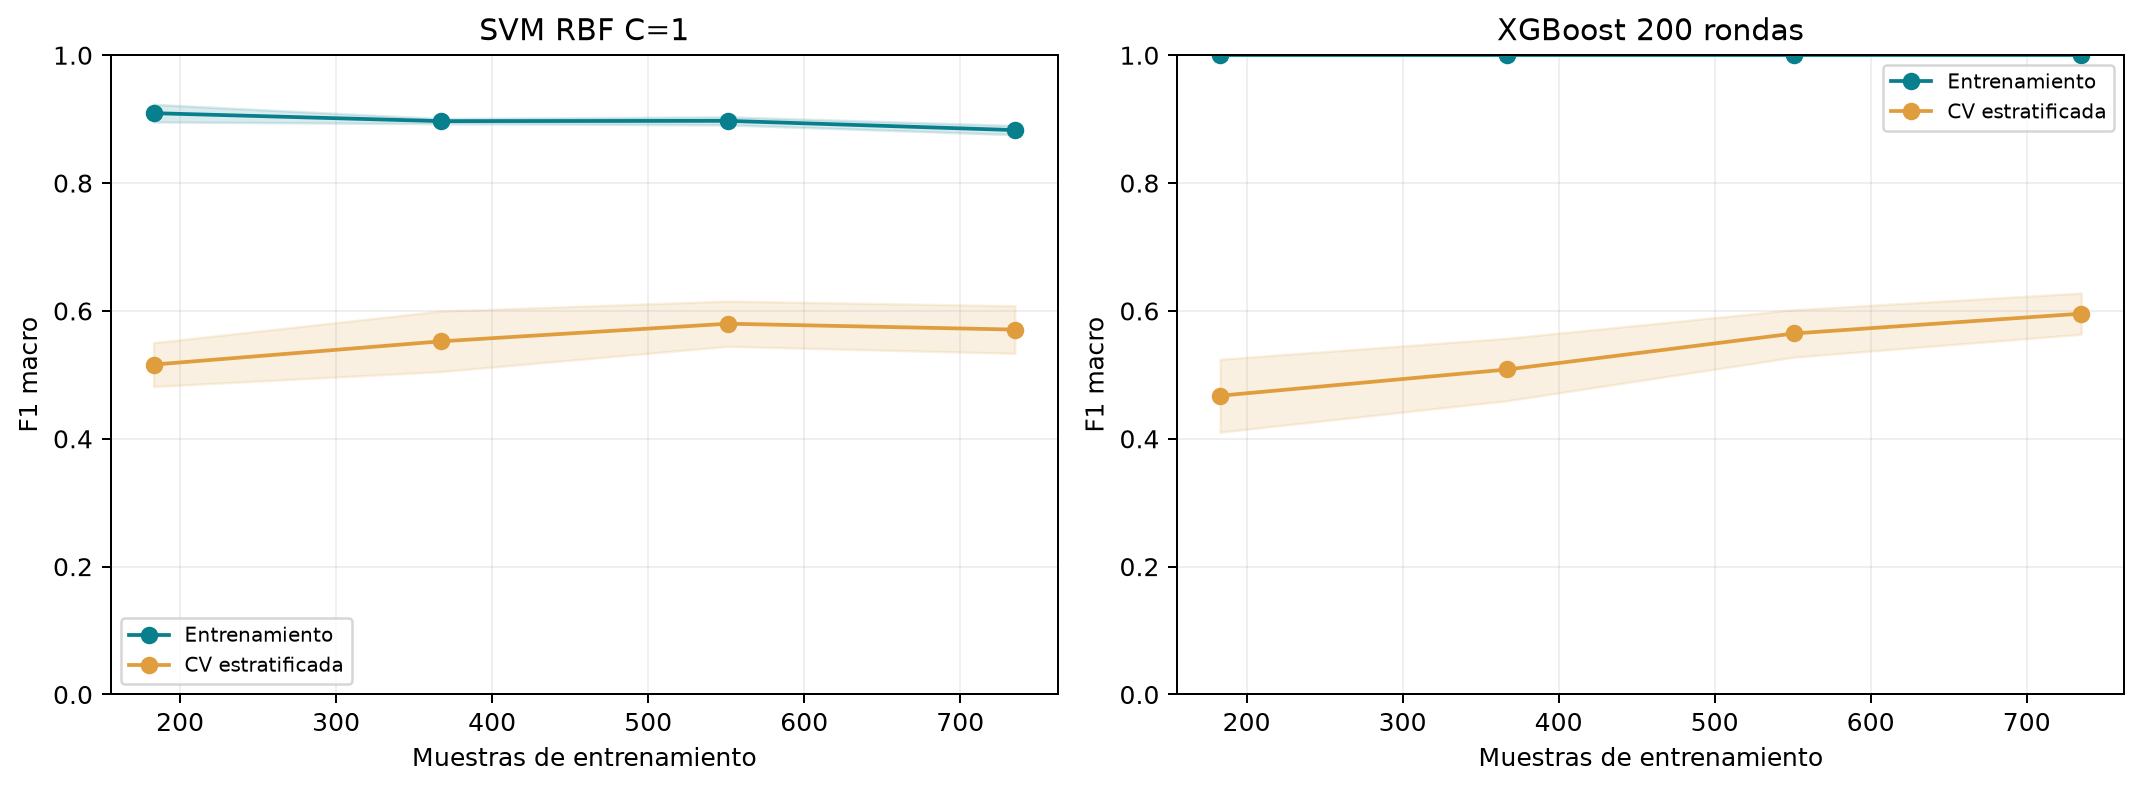

,model,train_f1,cv_f1
0,SVM RBF C=1,0.882844,0.570804
1,XGBoost 200 rondas,1.000000,0.595719


In [16]:
curves = []

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

curve_names = (
    [chosen, xgb_name]
    if chosen != xgb_name
    else [chosen, family_winners[family_winners.family == "SVM"].iloc[0].Modelo]
)

for ax, name in zip(axes, curve_names):
    kind = validation[validation.Modelo == name].iloc[0].input_kind
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=FutureWarning)
        n, tr, va = learning_curve(
            clone(models[name]),
            a[f"X_train_{kind}"],
            a["y_train"],
            train_sizes=[0.25, 0.5, 0.75, 1.0],
            cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
            scoring="f1_macro",
            n_jobs=1,
        )
    for values, label, color in [
        (tr, "Entrenamiento", "#087f8c"),
        (va, "CV estratificada", "#df9d3e"),
    ]:
        mean = values.mean(axis=1)
        std = values.std(axis=1)
        ax.plot(n, mean, "o-", label=label, color=color)
        ax.fill_between(n, mean - std, mean + std, alpha=0.15, color=color)
    ax.set(
        title=name, xlabel="Muestras de entrenamiento", ylabel="F1 macro", ylim=(0, 1)
    )
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
    curves.append(
        dict(
            model=name,
            train_f1=float(tr.mean(axis=1)[-1]),
            cv_f1=float(va.mean(axis=1)[-1]),
        )
    )

plt.tight_layout()

figure("modelos_avanzados_learning_curves.png")

save_json(REPORTS / "learning_curves_summary.json", curves)

display(pd.DataFrame(curves))


## 17. Comprobar las predicciones publicadas

Se contrasta el resultado reproducido con el protocolo vigente. La comprobación detecta cambios inesperados; no hace una nueva búsqueda de parámetros usando test.

In [17]:
assert chosen == "SVM RBF C=1"
assert abs(final_row["F1 Macro"] - 0.715544) < 1e-6
print("Reproducido:", chosen, "F1 macro test:", final_row["F1 Macro"])


Reproducido: SVM RBF C=1 F1 macro test: 0.715544


## Conclusiones y límites

El resultado vigente es SVM RBF C=1 con las 288 variables. Menos relleno no mejoró todas las métricas de test. Hay sobreajuste, ausencia de IDs de paciente y de evaluación externa, posible sesgo de formato y pérdida de lateralidad. GitHub Pages presenta muestras precalculadas; Streamlit/FastAPI permiten inferencia. No es un sistema validado para diagnóstico.